In [218]:
import numpy as np
import pandas as pd
import tensorflow as tf
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils import class_weight


from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

import nltk
from nltk.stem import WordNetLemmatizer


import matplotlib as plt

In [219]:
data = pd.read_csv('../data/blooms_taxonomy_dataset.csv', encoding='latin-1')

# cleaning

data["Questions"] = data["Questions"].str.lower().str.replace(r'[^\w\s]', '', regex=True)

X = data["Questions"]
y = data["Category"]

In [220]:
#labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(np.unique(y_encoded))

print(f"Detected {num_classes} classes: {label_encoder.classes_}")

Detected 6 classes: ['BT1' 'BT2' 'BT3' 'BT4' 'BT5' 'BT6']


In [221]:
#data split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)


In [222]:
#vectorization
max_features = 1000 
# vectorizer = TfidfVectorizer(stop_words='english', max_features=max_features, ngram_range=(1,2))
vectorizer = TfidfVectorizer(max_features=2000, ngram_range=(1,3))

X_train_tfidf = vectorizer.fit_transform(X_train).toarray()
X_test_tfidf = vectorizer.transform(X_test).toarray()

print(f"Shape of training data: {X_train_tfidf.shape}")

Shape of training data: (8380, 2000)


In [223]:
model = Sequential([
    Dense(128, activation='relu', kernel_regularizer=l2(0.01), input_shape=(X_train_tfidf.shape[1],)),
    BatchNormalization(),
    Dropout(0.6),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    BatchNormalization(),
    Dropout(0.6),
    Dense(num_classes, activation='softmax')
])


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [224]:
model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss=SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [225]:
weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
dict_weights = dict(enumerate(weights))


early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    X_train_tfidf, y_train,
    epochs=20,
    validation_data=(X_test_tfidf, y_test),
    callbacks=[early_stop],
    class_weight=dict_weights
)

Epoch 1/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3076 - loss: 4.3024 - val_accuracy: 0.1675 - val_loss: 3.6391
Epoch 2/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5521 - loss: 2.9869 - val_accuracy: 0.6579 - val_loss: 2.7049
Epoch 3/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6630 - loss: 2.4224 - val_accuracy: 0.7667 - val_loss: 2.0834
Epoch 4/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7123 - loss: 2.0356 - val_accuracy: 0.7686 - val_loss: 1.8111
Epoch 5/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7524 - loss: 1.7169 - val_accuracy: 0.7877 - val_loss: 1.5695
Epoch 6/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7749 - loss: 1.4810 - val_accuracy: 0.7839 - val_loss: 1.3993
Epoch 7/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7887 - loss: 1.2850 - val_accuracy: 0.7853 - val_loss: 1.2621
Epoch 8/20
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7982 - loss: 1.1505 - val_accuracy: 0.

In [226]:
loss, accuracy = model.evaluate(X_test_tfidf, y_test)
print(f"Test Accuracy: {accuracy*100:.2f}%")

66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 530us/step - accuracy: 0.8010 - loss: 0.9135
Test Accuracy: 80.10%


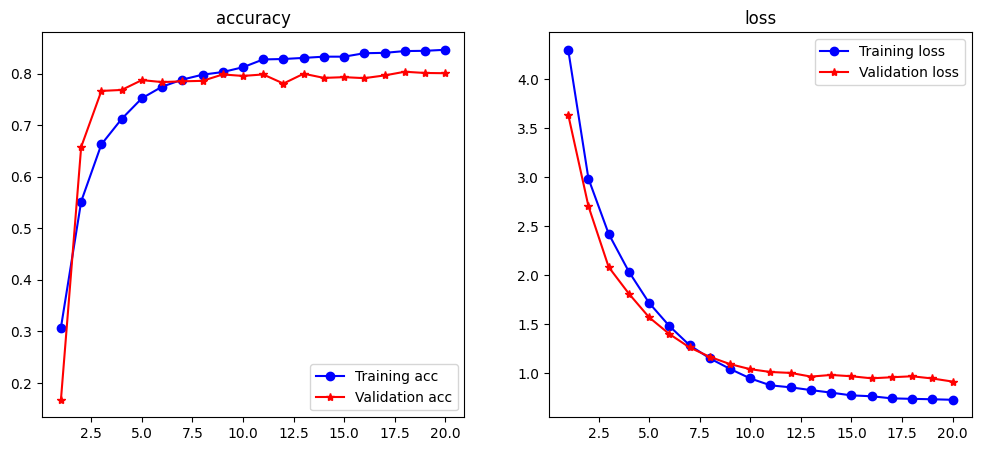

In [227]:
import matplotlib.pyplot as plt

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training acc')
    plt.plot(epochs, val_acc, 'r*-', label='Validation acc')
    plt.title('accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training loss')
    plt.plot(epochs, val_loss, 'r*-', label='Validation loss')
    plt.title('loss')
    plt.legend()

    plt.show()

plot_history(history)

In [229]:


def predict_bloom_level(new_question):
    clean_q = re.sub(r'[^\w\s]', '', new_question.lower())
    
    vec_q = vectorizer.transform([clean_q]).toarray()
    prediction_probs = model.predict(vec_q, verbose=0)
    predicted_index = np.argmax(prediction_probs)
    
    predicted_label = label_encoder.inverse_transform([predicted_index])[0]
    return predicted_label

In [230]:
test_q = "Explain the properties of good estimator?"
print(f"Question: {test_q}")
print(f"Predicted Level: {predict_bloom_level(test_q)}")

test_q_2 = "Distinguish between Null and Alternative hypothesis.  "
print(f"Question: {test_q_2}")
print(f"Predicted Level: {predict_bloom_level(test_q_2)}")

Question: Explain the properties of good estimator?
Predicted Level: BT4
Question: Distinguish between Null and Alternative hypothesis.  
Predicted Level: BT4
